In [69]:
# Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [70]:
from scipy import stats
from scipy.stats import chi2_contingency

In [71]:
# Loading Dataset
df = pd.read_csv("Dataset/1651277648862_healthinsurance.csv")

In [72]:
# Understanding of Dataset
df.shape



(15000, 13)

In [73]:
df.size


195000

In [74]:
df.columns

Index(['age', 'sex', 'weight', 'bmi', 'hereditary_diseases',
       'no_of_dependents', 'smoker', 'city', 'bloodpressure', 'diabetes',
       'regular_ex', 'job_title', 'claim'],
      dtype='str')

In [75]:
df.head(5)

,age,sex,weight,bmi,hereditary_diseases,no_of_dependents,smoker,city,bloodpressure,diabetes,regular_ex,job_title,claim
0,60.0,male,64,24.3,NoDisease,1,0,NewYork,72,0,0,Actor,13112.6
1,49.0,female,75,22.6,NoDisease,1,0,Boston,78,1,1,Engineer,9567.0
2,32.0,female,64,17.8,Epilepsy,2,1,Phildelphia,88,1,1,Academician,32734.2
3,61.0,female,53,36.4,NoDisease,1,1,Pittsburg,72,1,0,Chef,48517.6
4,19.0,female,50,20.6,NoDisease,0,0,Buffalo,82,1,0,HomeMakers,1731.7


In [76]:
df.tail(5)

,age,sex,weight,bmi,hereditary_diseases,no_of_dependents,smoker,city,bloodpressure,diabetes,regular_ex,job_title,claim
14995,39.0,male,49,28.3,NoDisease,1,1,Florence,54,1,0,FilmMaker,21082.2
14996,39.0,male,74,29.6,NoDisease,4,0,Miami,64,1,0,Student,7512.3
14997,20.0,male,62,33.3,NoDisease,0,0,Tampa,52,1,0,FashionDesigner,1391.5
14998,52.0,male,88,36.7,NoDisease,0,0,PanamaCity,70,1,0,Farmer,9144.6
14999,52.0,male,57,26.4,NoDisease,3,0,Kingsport,72,1,0,Manager,25992.8


In [77]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  14604 non-null  float64
 1   sex                  15000 non-null  str    
 2   weight               15000 non-null  int64  
 3   bmi                  14044 non-null  float64
 4   hereditary_diseases  15000 non-null  str    
 5   no_of_dependents     15000 non-null  int64  
 6   smoker               15000 non-null  int64  
 7   city                 15000 non-null  str    
 8   bloodpressure        15000 non-null  int64  
 9   diabetes             15000 non-null  int64  
 10  regular_ex           15000 non-null  int64  
 11  job_title            15000 non-null  str    
 12  claim                15000 non-null  float64
dtypes: float64(3), int64(6), str(4)
memory usage: 1.5 MB


In [78]:
df.isnull().sum()

age                    396
sex                      0
weight                   0
bmi                    956
hereditary_diseases      0
no_of_dependents         0
smoker                   0
city                     0
bloodpressure            0
diabetes                 0
regular_ex               0
job_title                0
claim                    0
dtype: int64

In [79]:
df.describe()

,age,weight,bmi,no_of_dependents,smoker,bloodpressure,diabetes,regular_ex,claim
count,14604.000000,15000.000000,14044.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,39.547521,64.909600,30.266413,1.129733,0.198133,68.650133,0.777000,0.224133,13401.437620
std,14.015966,13.701935,6.122950,1.228469,0.398606,19.418515,0.416272,0.417024,12148.239619
min,18.000000,34.000000,16.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1121.900000
25%,27.000000,54.000000,25.700000,0.000000,0.000000,64.000000,1.000000,0.000000,4846.900000
50%,40.000000,63.000000,29.400000,1.000000,0.000000,71.000000,1.000000,0.000000,9545.650000
75%,52.000000,76.000000,34.400000,2.000000,0.000000,80.000000,1.000000,0.000000,16519.125000
max,64.000000,95.000000,53.100000,5.000000,1.000000,122.000000,1.000000,1.000000,63770.400000


In [80]:
df.describe(include='object')

C:\Users\ajais\AppData\Local\Temp\ipykernel_20088\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,sex,hereditary_diseases,city,job_title
count,15000,15000,15000,15000
unique,2,10,91,35
top,female,NoDisease,Nashville,Student
freq,7652,13998,302,1320


In [81]:
# Data quality Analysis

In [82]:
# Check missing values
df.isnull().sum()

age                    396
sex                      0
weight                   0
bmi                    956
hereditary_diseases      0
no_of_dependents         0
smoker                   0
city                     0
bloodpressure            0
diabetes                 0
regular_ex               0
job_title                0
claim                    0
dtype: int64

In [83]:
# Missing value percentage
(df.isnull().sum() / len(df)) * 100

age                    2.640000
sex                    0.000000
weight                 0.000000
bmi                    6.373333
hereditary_diseases    0.000000
no_of_dependents       0.000000
smoker                 0.000000
city                   0.000000
bloodpressure          0.000000
diabetes               0.000000
regular_ex             0.000000
job_title              0.000000
claim                  0.000000
dtype: float64

In [16]:
# Check duplicate rows
df.duplicated().sum()

np.int64(1096)

In [17]:
# Check unique values
df.nunique()

age                      47
sex                       2
weight                   58
bmi                     269
hereditary_diseases      10
no_of_dependents          6
smoker                    2
city                     91
bloodpressure            69
diabetes                  2
regular_ex                2
job_title                35
claim                  2054
dtype: int64

In [18]:
# Check categorical columns
df.select_dtypes(include="object").columns

C:\Users\ajais\AppData\Local\Temp\ipykernel_20088\1938991597.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include="object").columns


Index(['sex', 'hereditary_diseases', 'city', 'job_title'], dtype='str')

In [19]:
# Check numerical columns
df.select_dtypes(include=np.number).columns

Index(['age', 'weight', 'bmi', 'no_of_dependents', 'smoker', 'bloodpressure',
       'diabetes', 'regular_ex', 'claim'],
      dtype='str')

In [20]:
# Handling Missing  Values

In [21]:
df.isnull().sum()

age                    396
sex                      0
weight                   0
bmi                    956
hereditary_diseases      0
no_of_dependents         0
smoker                   0
city                     0
bloodpressure            0
diabetes                 0
regular_ex               0
job_title                0
claim                    0
dtype: int64

In [22]:
df["age"] = df["age"].fillna(df["age"].median())

df["bmi"] = df["bmi"].fillna(df["bmi"].median())


df.isnull().sum()

age                    0
sex                    0
weight                 0
bmi                    0
hereditary_diseases    0
no_of_dependents       0
smoker                 0
city                   0
bloodpressure          0
diabetes               0
regular_ex             0
job_title              0
claim                  0
dtype: int64

In [23]:
# Duplicate Analysis

In [24]:
print("Duplicate rows:", df.duplicated().sum())

# Display duplicate rows
df[df.duplicated()]

Duplicate rows: 1096


,age,sex,weight,bmi,hereditary_diseases,no_of_dependents,smoker,city,bloodpressure,diabetes,regular_ex,job_title,claim
605,46.0,female,68,29.4,NoDisease,2,0,LosAngeles,60,1,0,Dancer,8825.1
608,27.0,female,82,29.4,NoDisease,3,0,Oceanside,82,1,1,Architect,18804.8
898,48.0,female,67,33.1,Alzheimer,0,1,Cincinnati,70,1,0,ITProfessional,40974.2
919,26.0,male,56,23.7,NoDisease,2,0,Kingman,72,1,0,HomeMakers,3484.3
970,48.0,female,70,28.9,NoDisease,1,0,KanasCity,72,0,0,Architect,9249.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...
14966,46.0,male,46,22.3,NoDisease,0,0,Louisville,72,1,0,Academician,7147.1
14971,18.0,female,53,27.3,NoDisease,3,1,Boston,85,1,0,Student,18223.5
14987,47.0,male,94,47.5,NoDisease,1,0,Raleigh,61,1,0,Academician,8083.9
14989,44.0,male,90,38.1,NoDisease,1,0,Georgia,76,1,0,Engineer,7152.7


In [25]:
# Removing Duplicates

In [26]:
# Create a separate cleaned dataset
df_clean = df.drop_duplicates().copy()

In [27]:
# Reset index
df_clean.reset_index(drop=True, inplace=True)

C:\Users\ajais\AppData\Local\Temp\ipykernel_20088\2144369966.py:2: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_clean.reset_index(drop=True, inplace=True)


In [28]:
print("Original Shape:", df.shape)
print("Cleaned Shape:", df_clean.shape)

Original Shape: (15000, 13)
Cleaned Shape: (13904, 13)


In [29]:
print("Remaining Duplicates:",
      df_clean.duplicated().sum())

Remaining Duplicates: 0


In [30]:
df_clean.to_csv('processed_dataset')

In [31]:
# Outlier Analysis

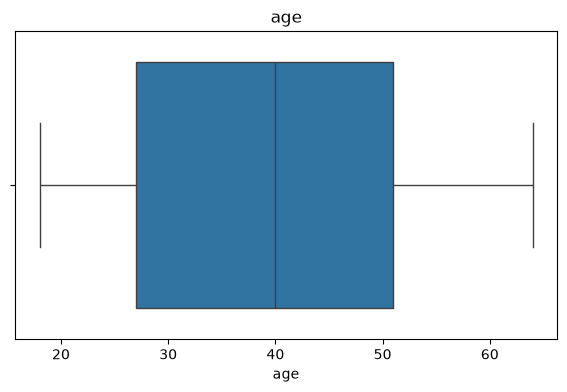

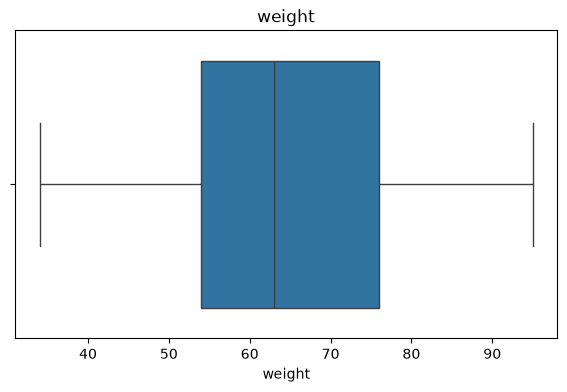

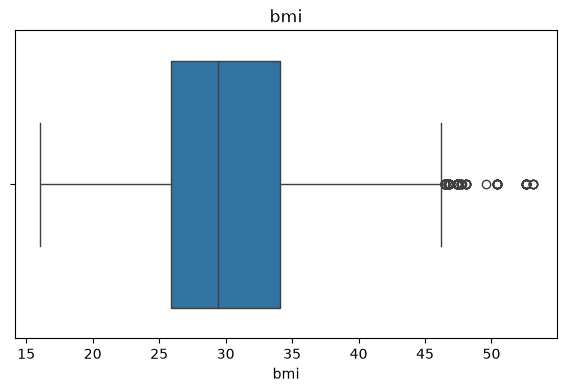

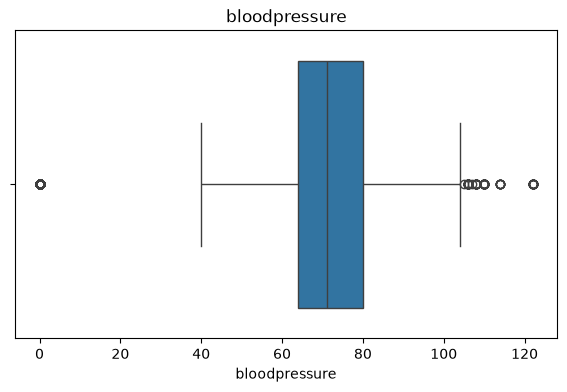

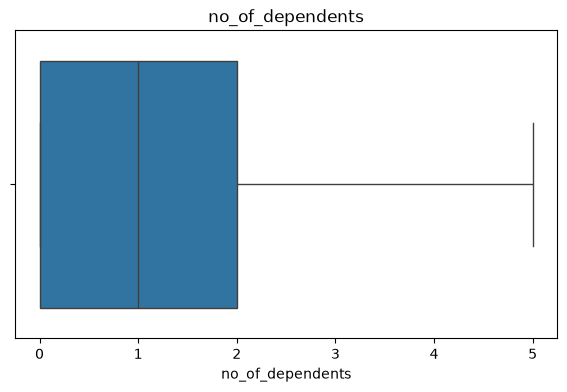

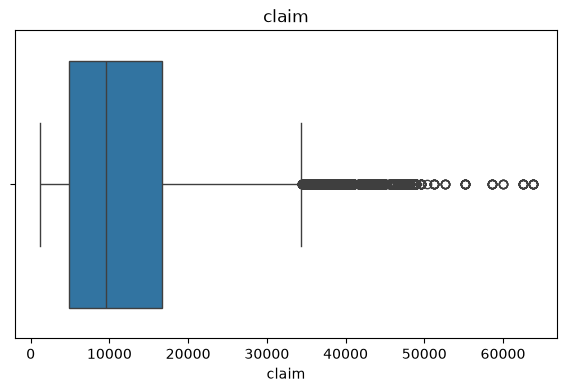

In [32]:
num_cols = [
    'age',
    'weight',
    'bmi',
    'bloodpressure',
    'no_of_dependents',
    'claim'
]
for col in num_cols:
    plt.figure(figsize=(7,4))
    sns.boxplot(x=df_clean[col])
    plt.title(col)
    plt.show()



In [33]:
# Categorical data analysis

In [34]:
# Unique values in categorical columns
categorical_columns = df_clean.select_dtypes(include="object").columns
for col in categorical_columns:
    print(f"\nColumn: {col}")
    print(df_clean[col].value_counts())


Column: sex
sex
female    7091
male      6813
Name: count, dtype: int64

Column: hereditary_diseases
hereditary_diseases
NoDisease       12965
Alzheimer         137
Diabetes          136
Obesity           130
EyeDisease        112
Cancer            107
Arthritis          88
HeartDisease       87
Epilepsy           77
High BP            65
Name: count, dtype: int64

Column: city
city
Nashville     270
Memphis       269
NewOrleans    268
Charleston    267
Brimingham    266
             ... 
York           68
Syracuse       67
Baltimore      67
Warwick        67
Trenton        66
Name: count, Length: 91, dtype: int64

Column: job_title
job_title
Student              1220
HomeMakers            899
Singer                697
FilmMaker             675
Actor                 662
Dancer                645
HouseKeeper           622
Manager               565
Police                381
Photographer          370
Beautician            363
Engineer              346
FashionDesigner       346
Accountant

C:\Users\ajais\AppData\Local\Temp\ipykernel_20088\740651772.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df_clean.select_dtypes(include="object").columns


In [35]:
# Numerical data analysis

In [36]:
# Numerical columns
numerical_columns = df_clean.select_dtypes(include=np.number).columns
# Distribution summary
df_clean[numerical_columns].describe()


,age,weight,bmi,no_of_dependents,smoker,bloodpressure,diabetes,regular_ex,claim
count,13904.000000,13904.000000,13904.000000,13904.000000,13904.000000,13904.000000,13904.000000,13904.000000,13904.000000
mean,39.568110,64.894347,30.216880,1.126438,0.200662,68.657652,0.771145,0.230725,13431.813744
std,13.828128,13.675070,5.927348,1.225661,0.400510,19.430514,0.420111,0.421312,12142.099413
min,18.000000,34.000000,16.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1121.900000
25%,27.000000,54.000000,25.900000,0.000000,0.000000,64.000000,1.000000,0.000000,4883.900000
50%,40.000000,63.000000,29.400000,1.000000,0.000000,71.000000,1.000000,0.000000,9567.000000
75%,51.000000,76.000000,34.100000,2.000000,0.000000,80.000000,1.000000,0.000000,16657.700000
max,64.000000,95.000000,53.100000,5.000000,1.000000,122.000000,1.000000,1.000000,63770.400000


In [37]:
# Univariate analysis

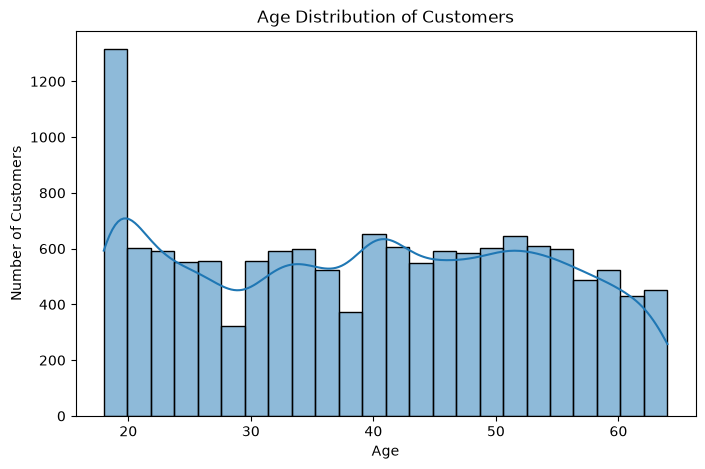

In [38]:
#  Age distribution
plt.figure(figsize=(8, 5))

sns.histplot(data=df_clean, x="age", kde=True)

plt.title("Age Distribution of Customers")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

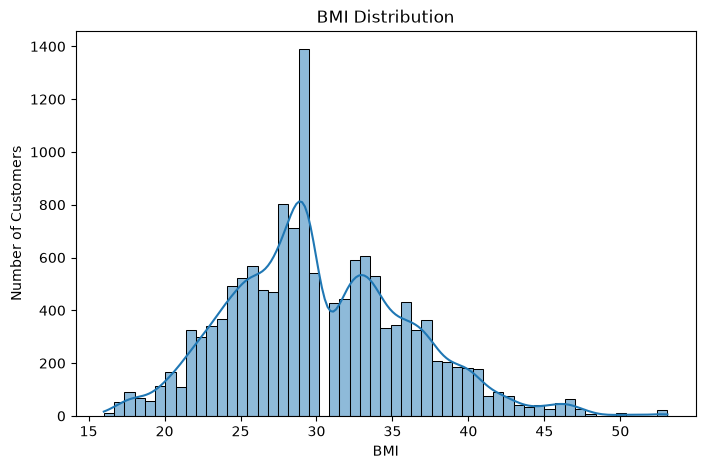

In [39]:
# BMI distribution
plt.figure(figsize=(8, 5))

sns.histplot(data=df_clean, x="bmi", kde=True)

plt.title("BMI Distribution")
plt.xlabel("BMI")
plt.ylabel("Number of Customers")

plt.show()

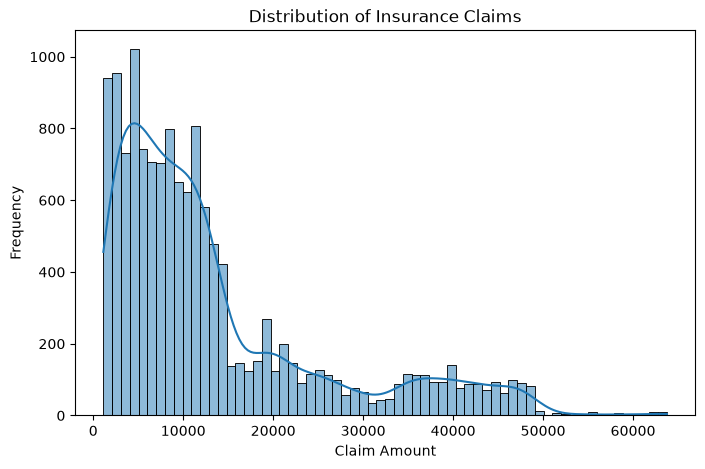

In [40]:
# Claim distribution
plt.figure(figsize=(8, 5))

sns.histplot(data=df_clean, x="claim", kde=True)

plt.title("Distribution of Insurance Claims")
plt.xlabel("Claim Amount")
plt.ylabel("Frequency")

plt.show()


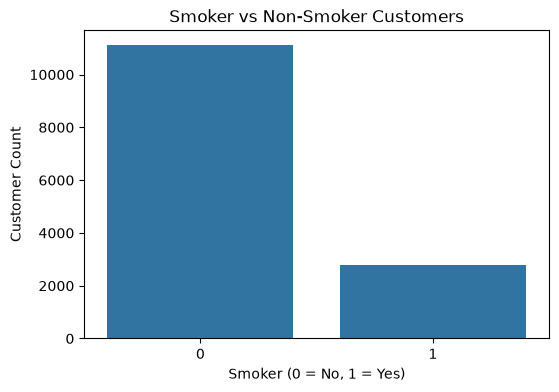

In [41]:
# Smoker distribution
plt.figure(figsize=(6, 4))

sns.countplot(data=df_clean, x="smoker")

plt.title("Smoker vs Non-Smoker Customers")
plt.xlabel("Smoker (0 = No, 1 = Yes)")
plt.ylabel("Customer Count")

plt.show()

In [42]:
# Bivariate analysis

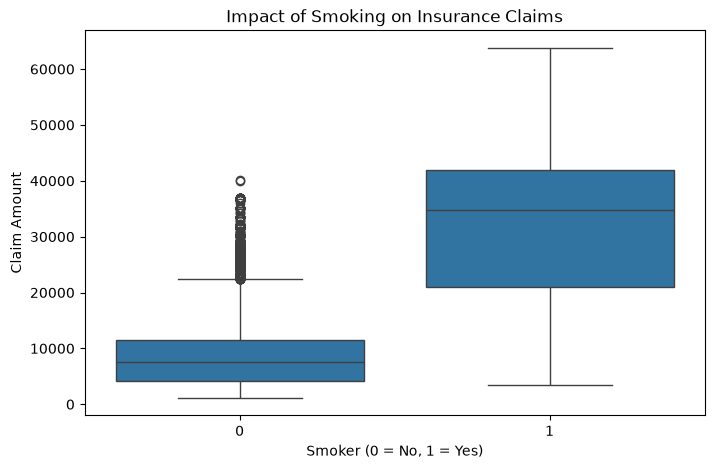

In [43]:
# Smoking status vs claim amount
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean, x="smoker", y="claim")

plt.title("Impact of Smoking on Insurance Claims")
plt.xlabel("Smoker (0 = No, 1 = Yes)")
plt.ylabel("Claim Amount")

plt.show() 

In [44]:
# Average claim by smoking status
df_clean.groupby("smoker")["claim"].mean()

smoker
0     8745.036513
1    32101.649642
Name: claim, dtype: float64

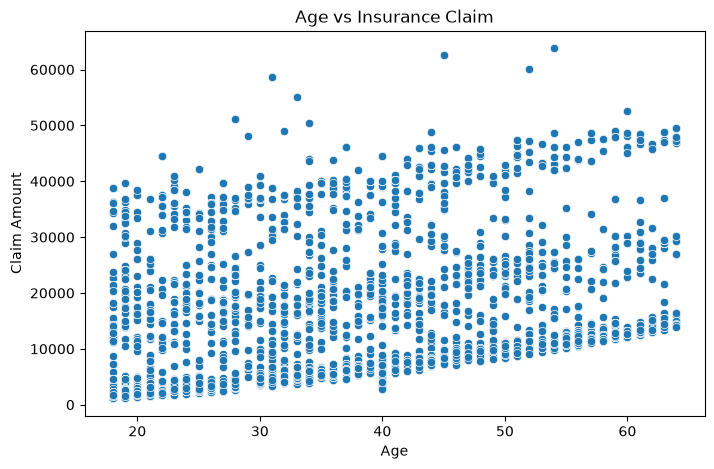

In [45]:
# Age vs claim amount
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df_clean, x="age", y="claim")

plt.title("Age vs Insurance Claim")
plt.xlabel("Age")
plt.ylabel("Claim Amount")

plt.show()

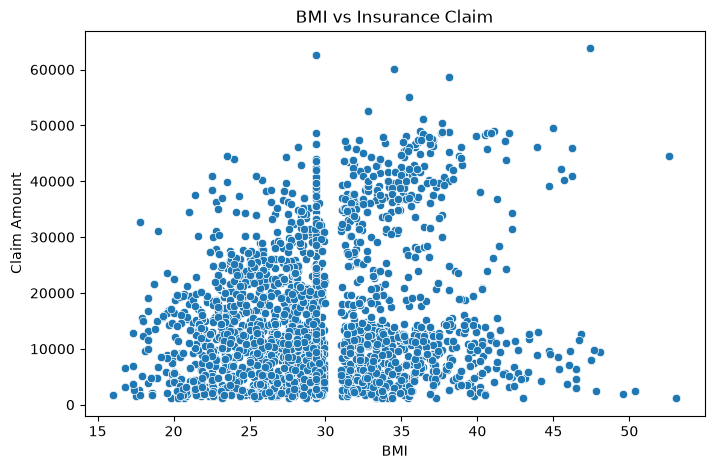

In [46]:
# BMI vs claim amount
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df_clean, x="bmi", y="claim")

plt.title("BMI vs Insurance Claim")
plt.xlabel("BMI")
plt.ylabel("Claim Amount")

plt.show()

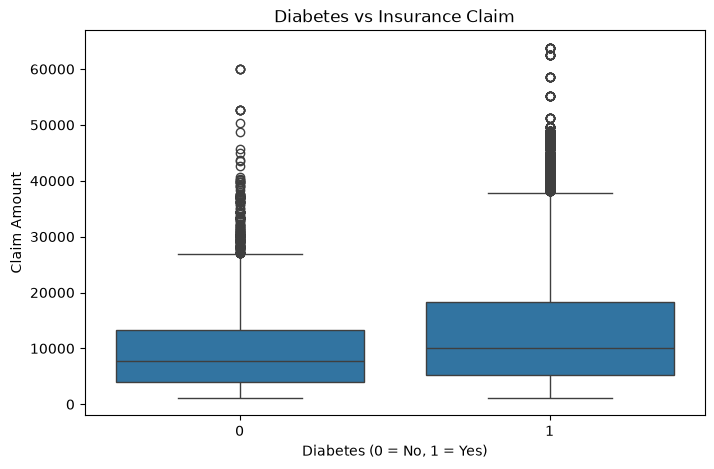

In [47]:
# Diabetes vs claim amount
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean, x="diabetes", y="claim")

plt.title("Diabetes vs Insurance Claim")
plt.xlabel("Diabetes (0 = No, 1 = Yes)")
plt.ylabel("Claim Amount")

plt.show()

In [48]:
# Multivariate analysis

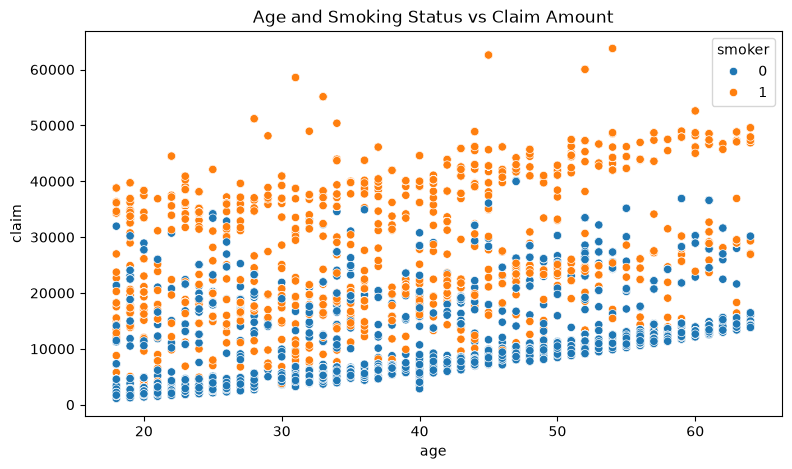

In [49]:
# Age and smoking status vs claim
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df_clean,
    x="age",
    y="claim",
    hue="smoker"
)

plt.title("Age and Smoking Status vs Claim Amount")
plt.show()


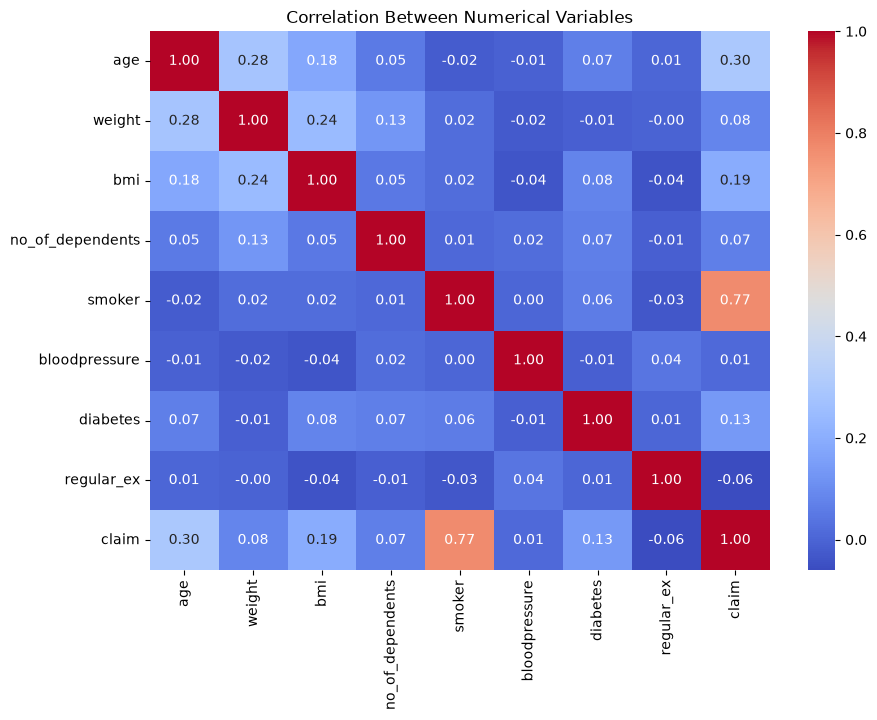

In [50]:
# Correlation heatmap
plt.figure(figsize=(10, 7))

correlation = df_clean.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Variables")
plt.show()

In [51]:
# Business insights

In [52]:
# Average claim by customer gender
df_clean.groupby("sex")["claim"].agg(
    ["mean", "median", "count"]
)

,mean,median,count
sex,,,
female,12748.322000,9541.7,7091
male,14143.194921,9617.7,6813


In [53]:
# Average claim by hereditary disease
df_clean.groupby("hereditary_diseases")["claim"].agg(
    ["mean", "median", "count"]
).sort_values(by="mean", ascending=False)

,mean,median,count
hereditary_diseases,,,
HeartDisease,43086.019540,44501.40,87
EyeDisease,41188.110714,42760.50,112
High BP,40605.910769,41661.60,65
Epilepsy,39692.058442,42983.50,77
Obesity,39589.330769,42211.10,130
Diabetes,39448.445588,39745.65,136
Cancer,39445.370093,38282.80,107
Alzheimer,37540.527007,38998.60,137
Arthritis,33899.270455,35595.60,88


In [54]:
# Average claim by diabetes
df_clean.groupby("diabetes")["claim"].agg(
    ["mean", "median", "count"]
)

,mean,median,count
diabetes,,,
0,10426.802577,7742.1,3182
1,14323.619894,10118.4,10722


In [55]:
# Average claim by exercise habit
df_clean.groupby("regular_ex")["claim"].agg(
    ["mean", "median", "count"]
)

,mean,median,count
regular_ex,,,
0,13833.078656,9361.3,10696
1,12093.930486,9872.7,3208


In [56]:
#  Average claim by job title
df_clean.groupby("job_title")["claim"].agg(
    ["mean", "median", "count"]
).sort_values(by="mean", ascending=False)

,mean,median,count
job_title,,,
Architect,16942.634421,10825.30,337
CEO,16895.202035,10807.50,344
Journalist,16406.960784,10197.80,255
Accountant,15953.736522,9957.70,345
Manager,15929.033628,12928.80,565
ITProfessional,15696.202761,9222.40,326
DataScientist,15632.620395,9144.45,304
FilmMaker,15589.002074,13937.70,675
Clerks,15448.815942,8964.10,345


In [57]:
#Create age groups
df_clean["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56-65",
        "65+"
    ]
)

df_clean.groupby("age_group", observed=True)["claim"].agg(
    ["mean", "median", "count"]
)

,mean,median,count
age_group,,,
18-25,13366.842750,9182.20,3062
26-35,13327.564450,9495.05,2616
36-45,13336.785075,9361.30,2995
46-55,13418.452037,9620.30,3019
56-65,13791.943580,10106.65,2212


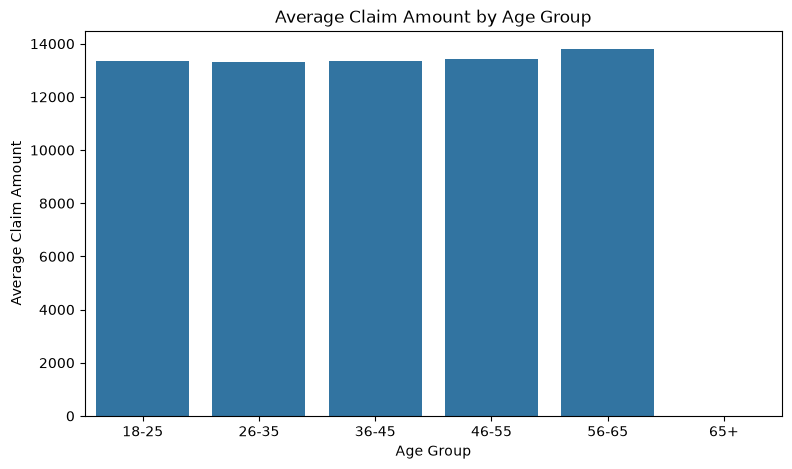

In [58]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_clean,
    x="age_group",
    y="claim",
    estimator="mean",
    errorbar=None
)

plt.title("Average Claim Amount by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Claim Amount")

plt.show()

In [59]:
# Identify high-claim customers
# 75th percentile of claim amount
claim_threshold = df_clean["claim"].quantile(0.75)

print("High claim threshold:", claim_threshold)

# Create claim category
df_clean["claim_category"] = np.where(
    df_clean["claim"] >= claim_threshold,
    "High Claim",
    "Normal Claim"
)

# Count customers in each category
df_clean["claim_category"].value_counts()

High claim threshold: 16657.7


claim_category
Normal Claim    10425
High Claim       3479
Name: count, dtype: int64

In [60]:
# Compare customer characteristics:
df_clean.groupby("claim_category").agg({
    "age": "mean",
    "bmi": "mean",
    "smoker": "mean",
    "diabetes": "mean",
    "claim": "mean"
})

,age,bmi,smoker,diabetes,claim
claim_category,,,,,
High Claim,40.632653,30.926416,0.723196,0.831848,31433.684565
Normal Claim,39.212854,29.980096,0.026283,0.750887,7424.282945


In [61]:
# Statistical analysis

In [62]:
# Correlation between age and claim
correlation, p_value = stats.pearsonr(
    df_clean["age"],
    df_clean["claim"]
)

print("Correlation:", correlation)
print("P-value:", p_value)

Correlation: 0.29730960328593614
P-value: 9.546563104160472e-282


In [63]:
# Compare claims of smokers and non-smokers
smoker_claims = df_clean[df_clean["smoker"] == 1]["claim"]
non_smoker_claims = df_clean[df_clean["smoker"] == 0]["claim"]

statistic, p_value = stats.mannwhitneyu(
    smoker_claims,
    non_smoker_claims,
    alternative="two-sided"
)

print("Statistic:", statistic)
print("P-value:", p_value)

Statistic: 29766913.0
P-value: 0.0


In [64]:
# BMI Risk Groups

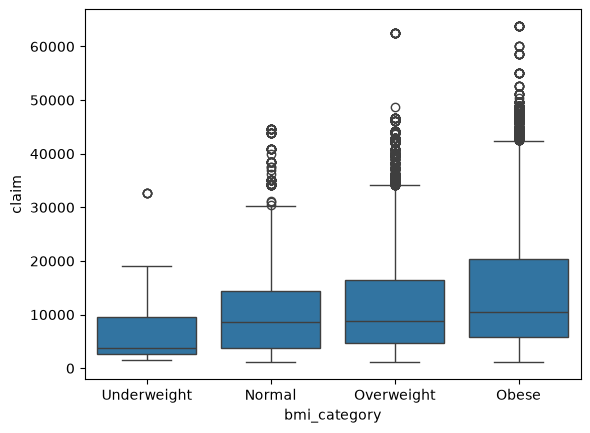

In [65]:
df_clean['bmi_category'] = pd.cut(
    df_clean['bmi'],
    bins=[0,18.5,25,30,100],
    labels=[
        'Underweight',
        'Normal',
        'Overweight',
        'Obese'
    ]
    )

sns.boxplot(
    data=df_clean,
    x='bmi_category',
    y='claim'
)
plt.show()


In [66]:
# Final EDA summary

In [67]:
print("Total Customers:", len(df_clean))

print("Average Claim:", df_clean["claim"].mean())

print("Median Claim:", df_clean["claim"].median())

print("Maximum Claim:", df_clean["claim"].max())

print("Minimum Claim:", df_clean["claim"].min())

print("Smoker Average Claim:")
print(df_clean.groupby("smoker")["claim"].mean())

print("Diabetes Average Claim:")
print(df_clean.groupby("diabetes")["claim"].mean())

print("Average Claim by Age Group:")
print(df_clean.groupby("age_group", observed=True)["claim"].mean())

Total Customers: 13904
Average Claim: 13431.813744246261
Median Claim: 9567.0
Maximum Claim: 63770.4
Minimum Claim: 1121.9
Smoker Average Claim:
smoker
0     8745.036513
1    32101.649642
Name: claim, dtype: float64
Diabetes Average Claim:
diabetes
0    10426.802577
1    14323.619894
Name: claim, dtype: float64
Average Claim by Age Group:
age_group
18-25    13366.842750
26-35    13327.564450
36-45    13336.785075
46-55    13418.452037
56-65    13791.943580
Name: claim, dtype: float64


In [68]:
df_clean.to_csv("final_fileInsurance")